**Linear Regression**

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv('D:\Python_VS_NTI\Housing.csv')
data.head()

<>:1: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
<>:1: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_15928\581643584.py:1: SyntaxWarning: "\P" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\P"? A raw string is also an option.
  data = pd.read_csv('D:\Python_VS_NTI\Housing.csv')


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [3]:
data.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='str')

In [4]:
from sklearn.linear_model import LinearRegression 

model = LinearRegression()

In [5]:
X = data.drop(columns=['price'])
#X = data[['area', 'rooms']]
y = data['price']

In [ ]:
X = pd.get_dummies(X, drop_first=True)

model.fit(X, y)

y_pred = model.predict(X)

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [8]:
# متوسط الخطأ المطلق (MAE)
ma = mean_absolute_error(y, y_pred)

# متوسط مربع الخطأ (MSE)
ms = mean_squared_error(y, y_pred)

# الجذر التربيعي لمتوسط مربع الخطأ (RMSE)
rms = np.sqrt(ms)

# معامل التحديد (R2 Score) - كلما اقترب من 1 كان النموذج أفضل
r2 = r2_score(y, y_pred)

print(f"Mean Absolute Error (MAE): {ma}")
print(f"Mean Squared Error (MSE): {ms}")
print(f"Root Mean Squared Error (RMSE): {rms}")
print(f"R2 Score: {r2}")

Mean Absolute Error (MAE): 775054.3287400283
Mean Squared Error (MSE): 1111187722284.4001
Root Mean Squared Error (RMSE): 1054128.892633344
R2 Score: 0.6818018485540142


Train Test Split

In [15]:
X = data[['area']]
y = data['price']


In [16]:
# 3. تقسيم البيانات إلى مجموعة تدريب (Train) ومجموعة اختبار (Test)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2, random_state=42)

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

w = model.coef_
b = model.intercept_

print("w (Coefficients):", w)
print("b (Intercept):", b)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae}")
print(f"R2 Score: {r2}")

w (Coefficients): [425.72984194]
b (Intercept): 2512254.2639593435
Mean Absolute Error (MAE): 1474748.1337969352
R2 Score: 0.27287851871974644


In [24]:
comp_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred , 'Difference': np.abs(y_test - y_pred)})

print(comp_df.head(10))

      Actual     Predicted    Difference
316  4060000  5.024060e+06  9.640603e+05
77   6650000  5.279498e+06  1.370502e+06
360  3710000  4.232203e+06  5.222028e+05
90   6440000  4.640903e+06  1.799097e+06
493  2800000  4.198144e+06  1.398144e+06
209  4900000  5.373159e+06  4.731588e+05
176  5250000  6.139473e+06  8.894725e+05
249  4543000  4.636646e+06  9.364618e+04
516  2450000  3.891619e+06  1.441619e+06
426  3353000  3.661725e+06  3.087248e+05


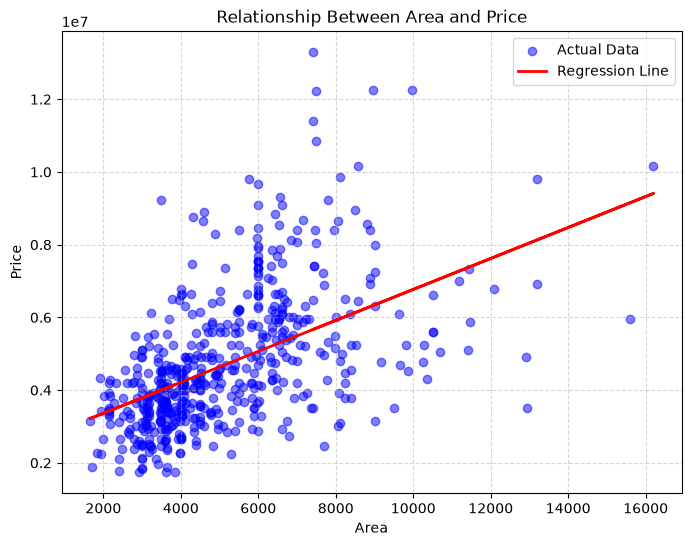

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

plt.scatter(data['area'], data['price'], color='blue', alpha=0.5, label='Actual Data')

plt.plot(data['area'], model.predict(data[['area']]), color='red', linewidth=2, label='Regression Line')

plt.xlabel('Area')
plt.ylabel('Price')
plt.title('Relationship Between Area and Price')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [30]:
X = data.drop(columns=['price'])
Y = data['price']

X = pd.get_dummies(X, drop_first=True)

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [37]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

coefficients_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient (w)': model.coef_
})

display(coefficients_df)


ma = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error: {ma}")
print(f"R-squared Score: {r2}")
print(f"Intercept (b): {model.intercept_}")

,Feature,Coefficient (w)
0,area,2.359688e+02
1,bedrooms,7.677870e+04
2,bathrooms,1.094445e+06
3,stories,4.074766e+05
4,parking,2.248419e+05
5,mainroad_yes,3.679199e+05
6,guestroom_yes,2.316100e+05
7,basement_yes,3.902512e+05
8,hotwaterheating_yes,6.846499e+05
9,airconditioning_yes,7.914267e+05


Mean Absolute Error: 970043.4039201637
R-squared Score: 0.6529242642153184
Intercept (b): 260032.35760741215


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline 
degree=2
model = make_pipeline(
    PolynomialFeatures(degree=degree, include_bias=False), LinearRegression())

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)
print(f"R-squared Score for Polynomial Regression (degree={degree}): {r2}")

R-squared Score for Polynomial Regression (degree=2): 0.6557341856744638


: 